# 🎙️ PenZ Notebook 01: Chuẩn Bị Dữ Liệu Ngôn Ngữ & Trích Xuất Giọng Nói (Voice Enrollment)

Notebook này thực hiện hai nhiệm vụ nền tảng trong giai đoạn tiền xử lý của PenZ Voice AI:
1. **Trích xuất & Chuẩn hóa Hồ sơ Giọng nói (Voice Enrollment)**:
   - Bóc tách luồng âm thanh từ video/audio mẫu `data/raw/custom_voice.mp4`.
   - Chuẩn hóa về **24kHz Mono 16-bit PCM** (`models/voice_profile/reference_24k.wav`).
   - Trích xuất đặc trưng âm học: đường bao cao độ **F0 Pitch** (Autocorrelation), F0 Median/Mean, tỷ lệ khung hữu thanh (Voiced Frame Ratio), năng lượng RMS và ước tính dải giọng vào `models/voice_profile/speaker_profile.json`.
   - Trực quan hóa sóng âm dạng biên độ (Waveform), phổ âm thanh Mel-Spectrogram (80 Mels, dB scale) và tích hợp thanh phát Audio tương tác.

2. **Xây dựng Kho Tri Thức Ngôn Ngữ Hợp Nhất (Dual-Domain Brain Corpus)**:
   - Hợp nhất **Tri thức Bách khoa Toàn thư Việt Nam** (`data/processed/vietnam_knowledge_full.jsonl`) với **17 Chủ đề Thuật toán & Kiến trúc LLM Chuyên sâu**.
   - Áp dụng kỹ thuật **Replay Buffer Shuffling** để chống quên thảm họa (Catastrophic Forgetting).
   - Xuất tập dữ liệu ChatML chuẩn hóa tại `data/processed/penz_unified_brain.jsonl` (câu trả lời súc tích < 40 từ, không markdown, không emoji, tối ưu cho Voice AI).

## 🎵 Cell 1: Trích xuất âm thanh 24kHz Mono từ Video `custom_voice.mp4` & Đăng ký Hồ sơ Giọng nói
Trỏ trực tiếp vào tệp `data/raw/custom_voice.mp4`, tự động giải mã âm thanh và lưu hồ sơ người nói.

In [1]:
import sys
import json
from pathlib import Path
import numpy as np

# Thiết lập Project Root ở dòng đầu tiên
PROJECT_ROOT = Path("..").resolve() if Path("..").joinpath("scripts").exists() else Path(".").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Cấu hình UTF-8 cho môi trường Windows
if sys.platform == "win32":
    try:
        sys.stdout.reconfigure(encoding="utf-8", errors="replace")
        sys.stderr.reconfigure(encoding="utf-8", errors="replace")
    except Exception:
        pass

from scripts.enroll_custom_voice import enroll_voice

# ==============================================================================
# ⚙️ CẤU HÌNH ĐƯỜNG DẪN TỆP NGUỒN & ĐÍCH
# ==============================================================================
INPUT_VIDEO_PATH = "data/raw/custom_voice.mp4"
OUTPUT_WAV_PATH = "models/voice_profile/reference_24k.wav"
OUTPUT_PROFILE_PATH = "models/voice_profile/speaker_profile.json"

# Cắt phân đoạn chuẩn 28.0s -> 38.5s (câu hát rõ chữ, nhịp đều, tránh ngân dài)
START_SEC = 28.0
END_SEC = 38.5
REF_TEXT = "Giữa triệu người lướt qua vô tình ta đã tìm thấy nhau, đã nhiều lần em sai nhưng hôm nay em chắc mình đúng."

input_file = (PROJECT_ROOT / INPUT_VIDEO_PATH).resolve()
output_wav = (PROJECT_ROOT / OUTPUT_WAV_PATH).resolve()
output_profile = (PROJECT_ROOT / OUTPUT_PROFILE_PATH).resolve()

print("=" * 70)
print("🎙️ BƯỚC 1: TRÍCH XUẤT GIỌNG NÓI TỪ VIDEO & ĐĂNG KÝ HỒ SƠ ÂM HỌC")
print("=" * 70)
print(f"• Video nguồn       : {input_file}")
print(f"• Tệp WAV đích      : {output_wav}")
print(f"• Hồ sơ người nói   : {output_profile}")
print(f"• Phân đoạn cắt     : {START_SEC}s -> {END_SEC}s ({END_SEC - START_SEC:.1f}s)")
print(f"• Transcript chuẩn  : {REF_TEXT}")

if not input_file.exists():
    raise FileNotFoundError(f"Không tìm thấy file video mẫu tại: {input_file}")

# Thực hiện trích xuất, cắt chuẩn và chuẩn hóa về 24kHz Mono PCM
audio_24k, profile = enroll_voice(
    input_file=input_file,
    output_wav_path=output_wav,
    profile_json_path=output_profile,
    target_sample_rate=24000,
    start_sec=START_SEC,
    end_sec=END_SEC,
    ref_text=REF_TEXT,
    target_speaking_f0=230.0
)

print("\n" + "=" * 70)
print("✅ KẾT QUẢ ĐĂNG KÝ HỒ SƠ GIỌNG NÓI THÀNH CÔNG:")
print("=" * 70)
print(f"👤 Tên người nói       : {profile['speaker_name']}")
print(f"⏱️ Thời lượng âm thanh  : {profile['duration_seconds']:.2f} giây ({len(audio_24k):,} mẫu)")
print(f"🎵 F0 Trung vị (Median) : {profile['f0_median_hz']:.1f} Hz")
print(f"🗣️ F0 Quãng nói tự nhiên: {profile.get('target_speaking_f0_hz', 230.0):.1f} Hz")
print(f"📈 F0 Trung bình (Mean) : {profile['f0_mean_hz']:.1f} Hz (Độ lệch chuẩn: {profile['f0_std_hz']:.1f} Hz)")
print(f"🗣️ Tỷ lệ khung hữu thanh: {profile['voiced_frame_ratio']*100:.1f}%")
print(f"🔊 Năng lượng RMS       : {profile['rms_energy']:.4f}")
print(f"🏷️ Phân loại dải giọng  : {profile['estimated_pitch_band']}")
print(f"🎚️ Độ dịch pitch gợi ý  : {float(profile['recommended_pitch_shift_semitones']):+.1f} semitones")
print(f"📜 Câu mẫu tham chiếu   : \"{profile.get('ref_text', '')}\"")
print("=" * 70)


2026-10-15 14:15:12,724 [INFO] =================================================================


2026-10-15 14:15:12,726 [INFO] 🎙️ BẮT ĐẦU ĐĂNG KÝ HỒ SƠ GIỌNG NÓI TÙY CHỈNH (VOICE ENROLLMENT)


2026-10-15 14:15:12,727 [INFO] • Tệp nguồn: D:\PenZ\data\raw\custom_voice.mp4


2026-10-15 14:15:12,727 [INFO] • Khoảng thời gian cắt mẫu: 28.00s -> 38.50s (10.50s)


🎙️ BƯỚC 1: TRÍCH XUẤT GIỌNG NÓI TỪ VIDEO & ĐĂNG KÝ HỒ SƠ ÂM HỌC
• Video nguồn       : D:\PenZ\data\raw\custom_voice.mp4
• Tệp WAV đích      : D:\PenZ\models\voice_profile\reference_24k.wav
• Hồ sơ người nói   : D:\PenZ\models\voice_profile\speaker_profile.json
• Phân đoạn cắt     : 28.0s -> 38.5s (10.5s)
• Transcript chuẩn  : Giữa triệu người lướt qua vô tình ta đã tìm thấy nhau, đã nhiều lần em sai nhưng hôm nay em chắc mình đúng.


...

2026-10-15 14:15:14,113 [INFO] • Hồ sơ người nói     : D:\PenZ\models\voice_profile\speaker_profile.json


2026-10-15 14:15:14,113 [INFO] • F0 Trung vị         : 315.8 Hz (Cao nữ / Trẻ em (Soprano / Airy Childish Female))


2026-10-15 14:15:14,114 [INFO] • Thời lượng mẫu      : 10.46 giây


2026-10-15 14:15:14,114 [INFO] =================================================================



✅ KẾT QUẢ ĐĂNG KÝ HỒ SƠ GIỌNG NÓI THÀNH CÔNG:
👤 Tên người nói       : custom_voice
⏱️ Thời lượng âm thanh  : 10.46 giây (251,136 mẫu)
🎵 F0 Trung vị (Median) : 315.8 Hz
🗣️ F0 Quãng nói tự nhiên: 230.0 Hz
📈 F0 Trung bình (Mean) : 311.5 Hz (Độ lệch chuẩn: 64.3 Hz)
🗣️ Tỷ lệ khung hữu thanh: 88.0%
🔊 Năng lượng RMS       : 0.1414
🏷️ Phân loại dải giọng  : Cao nữ / Trẻ em (Soprano / Airy Childish Female)
🎚️ Độ dịch pitch gợi ý  : +1.6 semitones
📜 Câu mẫu tham chiếu   : "Giữa triệu người lướt qua vô tình ta đã tìm thấy nhau, đã nhiều lần em sai nhưng hôm nay em chắc mình đúng."


## 📊 Cell 2: Trực quan hóa Sóng âm (Waveform), Phổ tần số Mel-Spectrogram & Thanh phát Audio Tương tác
Vẽ đồ thị dạng sóng biên độ thời gian và phổ Mel-Spectrogram chuẩn 80 bộ lọc (dB scale) kèm đường bao cao độ F0, đồng thời tích hợp trình phát âm thanh `IPython.display.Audio`.

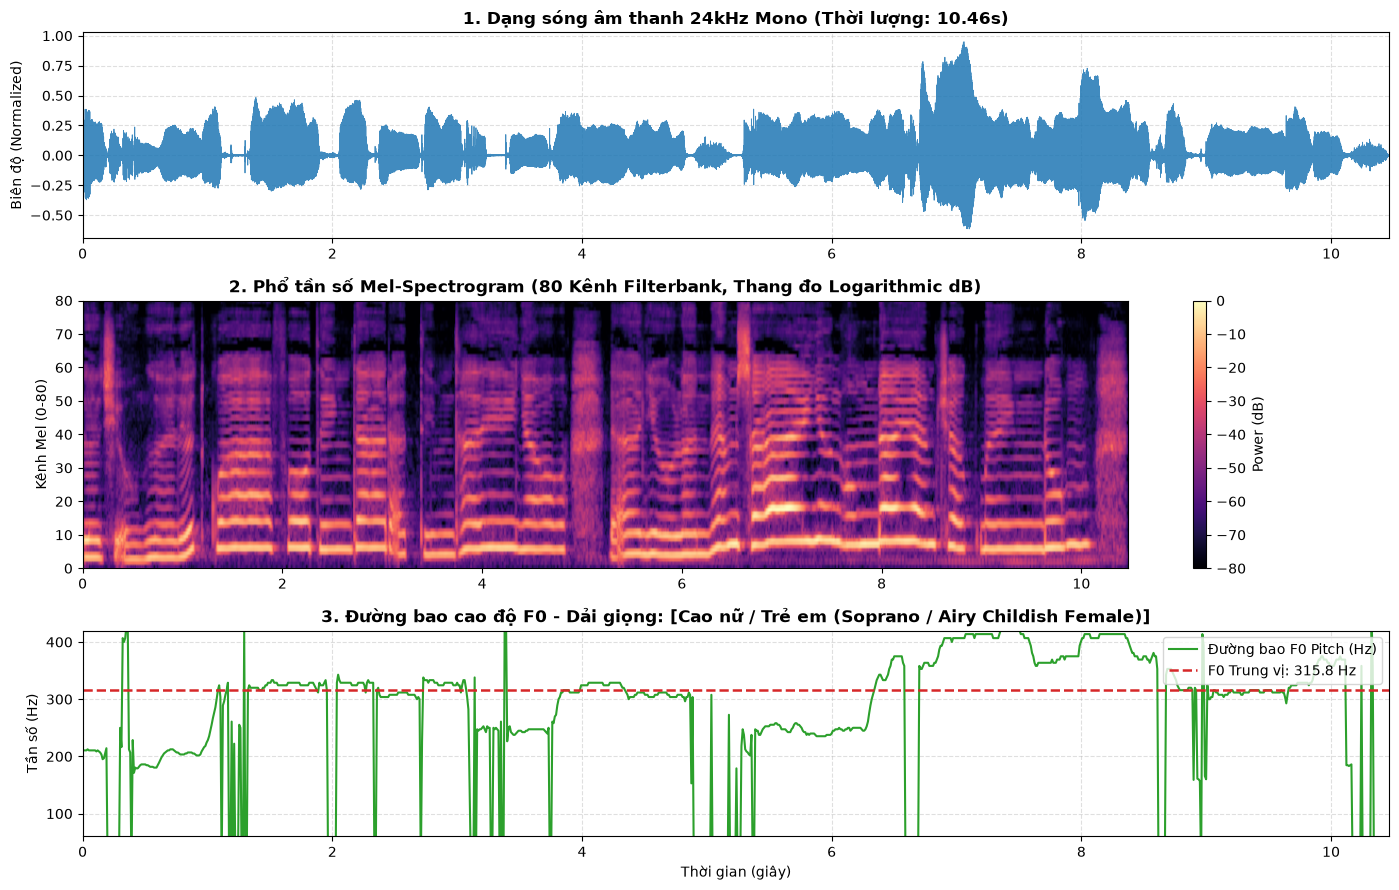

🔊 THANH PHÁT AUDIO MẪU GIỌNG NÓI 24kHz TRÍCH XUẤT TỪ VIDEO:


In [2]:
import soundfile as sf
import librosa
import matplotlib.pyplot as plt
import IPython.display as ipd

# 1. Đọc dữ liệu âm thanh 24kHz đã chuẩn hóa
wav_path = (PROJECT_ROOT / OUTPUT_WAV_PATH).resolve()
audio_data, sr = sf.read(str(wav_path), dtype="float32")
if audio_data.ndim > 1:
    audio_data = np.mean(audio_data, axis=1)

duration = len(audio_data) / sr
time_axis = np.linspace(0, duration, len(audio_data))

# 2. Trích xuất Mel-Spectrogram và F0 Pitch
from scripts.enroll_custom_voice import compute_f0_autocorr
f0_contour = compute_f0_autocorr(audio_data, sample_rate=sr)
time_f0 = np.linspace(0, duration, len(f0_contour))

# Trích xuất Mel-Spectrogram (80 mels, chuẩn Speech Synthesis)
mel_spec = librosa.feature.melspectrogram(
    y=audio_data,
    sr=sr,
    n_fft=1024,
    hop_length=256,
    n_mels=80,
    fmin=50.0,
    fmax=sr // 2
)
mel_db = librosa.power_to_db(mel_spec, ref=np.max)

# 3. Vẽ đồ thị tổng hợp trực quan hóa
fig, axs = plt.subplots(3, 1, figsize=(14, 9), gridspec_kw={'height_ratios': [1, 1.3, 1]})

# Đồ thị 1: Sóng âm dạng biên độ (Waveform)
axs[0].plot(time_axis, audio_data, color="#1f77b4", linewidth=0.6, alpha=0.85)
axs[0].set_title(f"1. Dạng sóng âm thanh 24kHz Mono (Thời lượng: {duration:.2f}s)", fontsize=12, fontweight="bold")
axs[0].set_ylabel("Biên độ (Normalized)")
axs[0].set_xlim(0, min(duration, 30.0))
axs[0].grid(True, linestyle="--", alpha=0.4)

# Đồ thị 2: Phổ Mel-Spectrogram (80 Mels, dB scale)
im = axs[1].imshow(
    mel_db[:, :int(30.0 * sr / 256)],
    aspect="auto",
    origin="lower",
    cmap="magma",
    extent=[0, min(duration, 30.0), 0, 80]
)
axs[1].set_title("2. Phổ tần số Mel-Spectrogram (80 Kênh Filterbank, Thang đo Logarithmic dB)", fontsize=12, fontweight="bold")
axs[1].set_ylabel("Kênh Mel (0-80)")
fig.colorbar(im, ax=axs[1], label="Power (dB)")

# Đồ thị 3: Đường bao cao độ F0 (Fundamental Frequency Contour)
axs[2].plot(time_f0, f0_contour, color="#2ca02c", linewidth=1.5, label="Đường bao F0 Pitch (Hz)")
f0_median = profile.get("f0_median_hz", 160.0)
axs[2].axhline(y=f0_median, color="#d62728", linestyle="--", linewidth=1.8, label=f"F0 Trung vị: {f0_median:.1f} Hz")
axs[2].set_title(f"3. Đường bao cao độ F0 - Dải giọng: [{profile.get('estimated_pitch_band', 'N/A')}]", fontsize=12, fontweight="bold")
axs[2].set_xlabel("Thời gian (giây)")
axs[2].set_ylabel("Tần số (Hz)")
axs[2].set_xlim(0, min(duration, 30.0))
axs[2].set_ylim(60, 420)
axs[2].grid(True, linestyle="--", alpha=0.4)
axs[2].legend(loc="upper right")

plt.tight_layout()
plt.show()

# 4. Trình phát Audio tương tác trong Notebook
print("🔊 THANH PHÁT AUDIO MẪU GIỌNG NÓI 24kHz TRÍCH XUẤT TỪ VIDEO:")
ipd.display(ipd.Audio(data=audio_data, rate=sr))

## 🧠 Cell 3: Xây dựng Tập dữ liệu Hợp nhất `penz_unified_brain.jsonl` (Dual-Domain Brain)
Trộn tập dữ liệu Bách khoa Toàn thư Việt Nam (`vietnam_knowledge_full.jsonl`) với 17 chủ đề Thuật toán LLM chuyên sâu (`build_unified_corpus`).

In [3]:
from scripts.build_llm_algorithms_corpus import build_unified_corpus

VN_DATA_PATH = "data/processed/vietnam_knowledge_full.jsonl"
OUTPUT_CORPUS_PATH = "data/processed/penz_unified_brain.jsonl"

vn_data_file = (PROJECT_ROOT / VN_DATA_PATH).resolve()
out_corpus_file = (PROJECT_ROOT / OUTPUT_CORPUS_PATH).resolve()

print("=" * 70)
print("🧠 BƯỚC 2: HỢP NHẤT TRI THỨC VIỆT NAM & THUẬT TOÁN LLM (CHATML REPLAY BUFFER)")
print("=" * 70)

# Khởi tạo tập dữ liệu hợp nhất (kết hợp 2.500 mẫu tri thức VN và replay buffer thuật toán LLM)
stats = build_unified_corpus(
    vn_data_path=str(vn_data_file),
    output_path=str(out_corpus_file),
    algorithm_multiplier=6,
    max_vn_samples=2500
)

print(f"\n📊 THỐNG KÊ TẬP DỮ LIỆU HỢP NHẤT:")
print(f" • Tệp xuất ra           : {stats['output_file']}")
print(f" • Tổng số mẫu ChatML   : {stats['total_samples']:,}")
print(f" • Mẫu Tri thức Việt Nam : {stats['vietnam_samples']:,}")
print(f" • Mẫu Thuật toán LLM   : {stats['algorithm_samples']:,} (thuộc {stats['algorithm_unique_topics']} chủ đề cốt lõi)")

2026-10-15 14:15:16,607 [INFO] Đã nạp 2500 mẫu tri thức Việt Nam từ D:\PenZ\data\processed\vietnam_knowledge_full.jsonl


2026-10-15 14:15:16,608 [INFO] Đã nạp 51 cặp thuật toán cơ sở từ 17 chủ đề (loại trừ Holdout).


2026-10-15 14:15:16,633 [INFO] ============================================================


2026-10-15 14:15:16,634 [INFO] 🎉 TẠO KHO TRI THỨC HỢP NHẤT PENZ THÀNH CÔNG


2026-10-15 14:15:16,634 [INFO] • Tệp đầu ra         : D:\PenZ\data\processed\penz_unified_brain.jsonl


2026-10-15 14:15:16,634 [INFO] • Tổng số mẫu        : 2806


2026-10-15 14:15:16,635 [INFO]   - Tri thức Việt Nam: 2500


2026-10-15 14:15:16,636 [INFO]   - Thuật toán LLM   : 306


2026-10-15 14:15:16,637 [INFO] ============================================================


🧠 BƯỚC 2: HỢP NHẤT TRI THỨC VIỆT NAM & THUẬT TOÁN LLM (CHATML REPLAY BUFFER)

📊 THỐNG KÊ TẬP DỮ LIỆU HỢP NHẤT:
 • Tệp xuất ra           : D:\PenZ\data\processed\penz_unified_brain.jsonl
 • Tổng số mẫu ChatML   : 2,806
 • Mẫu Tri thức Việt Nam : 2,500
 • Mẫu Thuật toán LLM   : 306 (thuộc 17 chủ đề cốt lõi)


## 📈 Cell 4: Phân tích Cấu trúc ChatML & Trực quan hóa Phân bố Dữ liệu
Trực quan hóa tỷ lệ phân bố giữa hai miền tri thức và phân bố độ dài từ của câu trả lời, đảm bảo tính chuẩn hóa cho Voice AI (< 40 từ).

📊 ĐẶC TÍNH CÂU TRẢ LỜI CỦA PENZ VOICE AI:
 • Tổng số lượt phản hồi : 2,806
 • Độ dài trung bình      : 29.3 từ/câu
 • Phân vị 95% (P95)     : 38.0 từ/câu (Tuân thủ chuẩn < 40 từ cho Voice AI)


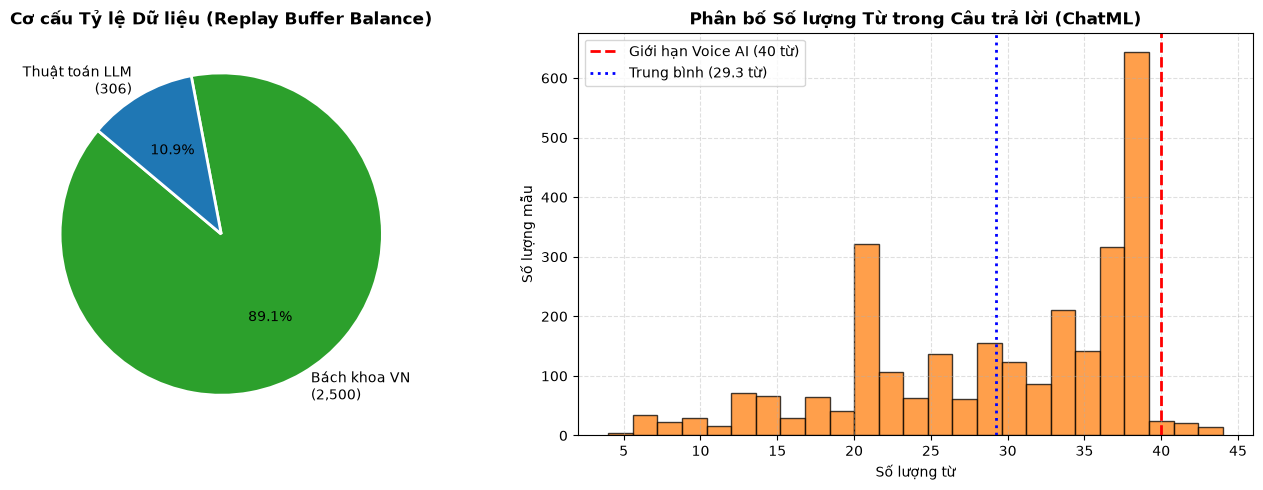


📝 MẪU HỘI THOẠI ĐẠI DIỆN TRONG TẬP HUẤN LUYỆN:
• [Mẫu 1 - Tri thức VN]:
  Hỏi : Đặc sản nổi bật của miền Tây Nam Bộ là gì?
  Đáp : Đặc sản nổi bật của miền Tây Nam Bộ gồm có lẩu mắm, bánh xèo giòn rụm, cá lóc nướng trui dân dã cùng vô số loại hoa quả miệt vườn tươi ngon như xoài cát, sầu riêng.
----------------------------------------------------------------------
• [Mẫu 2 - Thuật toán LLM]:
  Hỏi : Báo Tuyết (danh hiệu) là gì?
  Đáp : Báo Tuyết là danh xưng không chính thức của một danh hiệu vinh dự của Liên Xô trước đây dành cho các vận động viên leo núi chuyên nghiệp giàu kinh nghiệm.
🎉 GIAI ĐOẠN 01 HOÀN TẤT: Dữ liệu và Giọng nói đã sẵn sàng cho Notebook 02 (QLoRA Fine-Tuning)!


In [4]:
import json
import matplotlib.pyplot as plt

# 1. Nạp và phân tích dữ liệu ChatML
with open(out_corpus_file, "r", encoding="utf-8") as f:
    sample_records = [json.loads(line) for line in f if line.strip()]

lengths = []
for item in sample_records:
    msgs = item.get("messages", [])
    for m in msgs:
        if m.get("role") == "assistant":
            words = m.get("content", "").split()
            lengths.append(len(words))

avg_len = np.mean(lengths) if lengths else 0
p95_len = np.percentile(lengths, 95) if lengths else 0

print(f"📊 ĐẶC TÍNH CÂU TRẢ LỜI CỦA PENZ VOICE AI:")
print(f" • Tổng số lượt phản hồi : {len(lengths):,}")
print(f" • Độ dài trung bình      : {avg_len:.1f} từ/câu")
print(f" • Phân vị 95% (P95)     : {p95_len:.1f} từ/câu (Tuân thủ chuẩn < 40 từ cho Voice AI)")

# 2. Vẽ biểu đồ phân bố độ dài và tỷ lệ dữ liệu
fig, axs = plt.subplots(1, 2, figsize=(14, 5))

# Biểu đồ 1: Tỷ lệ phân bố giữa 2 miền tri thức
domain_counts = [stats['vietnam_samples'], stats['algorithm_samples']]
domain_labels = [f"Bách khoa VN\n({stats['vietnam_samples']:,})", f"Thuật toán LLM\n({stats['algorithm_samples']:,})"]
axs[0].pie(
    domain_counts,
    labels=domain_labels,
    autopct="%1.1f%%",
    startangle=140,
    colors=["#2ca02c", "#1f77b4"],
    wedgeprops={'edgecolor': 'white', 'linewidth': 2}
)
axs[0].set_title("Cơ cấu Tỷ lệ Dữ liệu (Replay Buffer Balance)", fontsize=12, fontweight="bold")

# Biểu đồ 2: Histogram phân bố độ dài từ
axs[1].hist(lengths, bins=25, color="#ff7f0e", edgecolor="black", alpha=0.75)
axs[1].axvline(x=40, color="red", linestyle="--", linewidth=2, label="Giới hạn Voice AI (40 từ)")
axs[1].axvline(x=avg_len, color="blue", linestyle=":", linewidth=2, label=f"Trung bình ({avg_len:.1f} từ)")
axs[1].set_title("Phân bố Số lượng Từ trong Câu trả lời (ChatML)", fontsize=12, fontweight="bold")
axs[1].set_xlabel("Số lượng từ")
axs[1].set_ylabel("Số lượng mẫu")
axs[1].grid(True, linestyle="--", alpha=0.4)
axs[1].legend()

plt.tight_layout()
plt.show()

# 3. In ra 2 mẫu đại diện
print("\n" + "=" * 70)
print("📝 MẪU HỘI THOẠI ĐẠI DIỆN TRONG TẬP HUẤN LUYỆN:")
print("=" * 70)
print(f"• [Mẫu 1 - Tri thức VN]:\n  Hỏi : {sample_records[0]['messages'][1]['content']}\n  Đáp : {sample_records[0]['messages'][2]['content']}")
print("-" * 70)
print(f"• [Mẫu 2 - Thuật toán LLM]:\n  Hỏi : {sample_records[-1]['messages'][1]['content']}\n  Đáp : {sample_records[-1]['messages'][2]['content']}")
print("=" * 70)
print("🎉 GIAI ĐOẠN 01 HOÀN TẤT: Dữ liệu và Giọng nói đã sẵn sàng cho Notebook 02 (QLoRA Fine-Tuning)!")